# Chronos2 자체 사전학습 준비와 학습용 backbone

**데이터 계약 → 부품·시간 분할 → 새 가중치 → H27 출력 → 합성 역전파**

대상: `ts_forecaster_lib` / `ts_forecaster_lib_v2` · 작성일: 2026-11-19

현재 완료한 1·2단계를 실제 프로젝트 클래스로 따라가는 학습용 노트북.
공식 사전학습 가중치 없이 작은 모델을 생성하고, 합성 배치로 한 번의 파라미터 갱신까지 확인하는 범위.

> 실제 수요 학습, DB 연결·쓰기, Hub 다운로드, GPU 실행, 체크포인트 저장은 없는 구성.
> 합성 예측과 1회 갱신은 구현 확인용이며 예측 성능이나 TSFM 완성의 증거와 구분.


## 목표와 읽는 순서

| 순서 | 확인할 질문 | 코드에서 관찰할 대상 |
|---|---|---|
| 1 | 0수요와 결측은 어떻게 다른가? | 원천 선언과 관측 마스크 |
| 2 | 학습·검증·시험은 어떻게 나누는가? | ID 배정, ISO 주차, 정답 cutoff |
| 3 | 공식 가중치 없이 모델을 만들었는가? | 내부 Raw source, 초기 가중치 해시, 출처 |
| 4 | 과거 52주로 미래 27주를 어떻게 출력하는가? | 16주 patch 2개, 32→27 자르기 |
| 5 | 실제로 학습 가능한 코드인가? | native 손실, gradient, 합성 AdamW 1회 |

가정: 실제 스냅샷의 0은 모두 관측된 무수요라는 사용자 확인에 따른 계약.
부품·정답 기간의 분리는 승인됐지만 수량 품질·이력 가용성·패턴별 sampler는 아직 후속 작업.


## 실행 준비

PyCharm/Jupyter에서 아래 의존성을 가진 커널을 선택한 뒤 **위에서부터 전체 실행**.
저장소 안의 어느 디렉토리에서 시작해도 루트를 찾도록 구성.

```bash
# 별도 개발 환경에서 필요한 경우에만 설치. 노트북 셀은 설치를 실행하지 않는 구성.
python -m pip install -e '.[chronos2-native,notebook]'
python -m pip install nbformat nbclient ipykernel matplotlib pandas
```

내부 소스 원본: 공식 v2.3.2 / 실행 의존성: `transformers==4.57.6`, `einops>=0.7,<1`, PyTorch.
외부 `chronos-forecasting` 없이 실행 가능한 구성. 실제 모델·Attention 코드는 `Chronos2/native/`에 포함.
이 노트북의 모델은 CPU·FP32이며, 해당 커널의 CPU 연산 스레드는 1개로 제한.


In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from importlib.metadata import version
from contextlib import ExitStack
from unittest.mock import patch
import hashlib
import json
import sys

# 노트북 폴더 또는 저장소 루트에서 실행 가능하도록 프로젝트 위치 탐색.
roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
REPO_ROOT = next((root for root in roots
                  if (root / "src/modeling_module/models/Chronos2").is_dir()
                  and (root / "pyproject.toml").is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError("ts_forecaster_lib 저장소 안에서 커널을 시작해야 합니다.")
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display, Markdown

get_ipython().run_line_magic("matplotlib", "inline")
torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 120, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
print("현재 Python:", sys.executable)
display(pd.DataFrame({"패키지": ["torch", "einops", "transformers", "numpy"],
                      "버전": [version(name) for name in
                               ("torch", "einops", "transformers", "numpy")]}))


현재 Python: /private/tmp/ts-forecaster-chronos2-native-env-20261119/bin/python


,패키지,버전
0,torch,2.9.1
1,einops,0.8.2
2,transformers,4.57.6
3,numpy,2.1.3


### 실행 설정과 코드 책임

기본 설정은 소형 계약 검증용 모델이며 공식 사전학습 모델과 다른 크기.
여기서는 더 작은 1층 모델을 사용해 순전파와 gradient를 빠르게 관찰하는 구성.
`dropout_rate=0`은 마스크·미래 정답 변경의 영향을 정확히 비교하기 위한 실습 설정이며 운영 권장값과 구분.

| 파일 | 역할 |
|---|---|
| `training/configs.py` | 모델 크기·길이·분위수·seed |
| `training/contracts.py` | 원천 선언·식별자·분할·정답 cutoff |
| `training/batch.py` | 수요·관측 마스크·독립 group·출력 계약 |
| `trainable_backbone.py` | 내부 모델 생성자와 학습 가능한 native forward |
| `native/model.py`, `native/layers.py` | 실제 Encoder·Attention·예측 head·손실 연산 |
| `native/preprocessing.py`, `native/config.py` | 정규화·패치 처리·모델 구조 설정 |
| 기존 `backbone.py` | 공식 가중치 동결 zero-shot, 이번 실습에서 미사용 |


In [2]:
from modeling_module.models.Chronos2.training import (
    Chronos2DataContract, Chronos2TrainableConfig, Chronos2TrainingBatch,
    Chronos2SplitContract, ForecastPartition, ForecastWindow, SeriesKey,
)
from modeling_module.models.Chronos2.training.contracts import (
    make_split_contract, manifest_sha256,
)
from modeling_module.models.Chronos2.trainable_backbone import Chronos2TrainableBackbone
from modeling_module.data_loader.temporal import add_period

SEED, LOOKBACK, HORIZON = 42, 52, 27
default_config = Chronos2TrainableConfig()
demo_config = replace(default_config, context_length=LOOKBACK, horizon=HORIZON,
                      d_model=32, d_ff=64, num_layers=1, num_heads=4, d_kv=8,
                      dropout_rate=0.0, seed=SEED, device="cpu")
settings = ("context_length", "horizon", "patch_size", "d_model", "d_ff",
            "num_layers", "num_heads", "dropout_rate", "device")
display(pd.DataFrame({"설정": settings,
                      "기본 모델": [getattr(default_config, key) for key in settings],
                      "실습 모델": [getattr(demo_config, key) for key in settings]}))


,설정,기본 모델,실습 모델
0,context_length,52,52
1,horizon,27,27
2,patch_size,16,16
3,d_model,128,32
4,d_ff,256,64
5,num_layers,2,1
6,num_heads,4,4
7,dropout_rate,0.1,0.0
8,device,cpu,cpu


## 1. 원천 선언과 0수요 의미

`observed_zero`는 0을 실제 무수요로 취급하는 선언.
`unconfirmed` 또는 `unverified`이면 의미 확인 없이 실제 학습을 진행하지 못하도록 확인 메서드에서 거부.
선언만으로 parquet 수량이 정상이라고 판정하거나 학습 승인을 대체하지 않는 경계.

아래는 **합성 계약 예제**. 사용한 해시는 예제 문자열의 해시이며 실제 parquet 해시와 구분.
부품 ID는 문자열로 유지하고, 법인·사이트가 추가되면 `SeriesKey` 복합키 사용 가능.


In [3]:
def expect_rejection(label, operation):
    # 예상된 계약 오류는 메시지로 표시하고, 거부되지 않으면 실습 실패 처리.
    try:
        operation()
    except (ValueError, TypeError) as error:
        return {"검사": label, "결과": "예상대로 거부", "메시지": str(error)}
    raise AssertionError(f"거부돼야 하는 입력이 통과했습니다: {label}")

synthetic_source = Chronos2DataContract(
    source_id="synthetic-notebook-contract-v1",
    source_sha256=hashlib.sha256(b"synthetic-notebook-contract-v1").hexdigest(),
    provenance="synthetic", zero_semantics="observed_zero",
)
synthetic_source.assert_semantics_confirmed()
unknown_source = replace(synthetic_source, provenance="unverified", zero_semantics="unconfirmed")
display(pd.DataFrame([expect_rejection("0수요 의미 미확인", unknown_source.assert_semantics_confirmed)]))
print("현재 예제:", synthetic_source.provenance, "/", synthetic_source.zero_semantics)
print("복합키 예:", SeriesKey(("DSE", "C110", "V110", "DEMO_001")))


,검사,결과,메시지
0,0수요 의미 미확인,예상대로 거부,출처와 0수요 의미를 확인하기 전에는 실제 데이터 학습을 진행할 수 없습니다.


현재 예제: synthetic / observed_zero
복합키 예: SeriesKey(values=('DSE', 'C110', 'V110', 'DEMO_001'))


## 2. 부품 70:15:15와 정답 기간 분리

부품 ID와 역할명을 seed와 함께 해시한 순위로 배정하며 수요량·패턴·오차는 미사용.
먼저 과거에 평가하지 않은 후보에서 시험 부품을 고른 뒤 검증·학습을 배정하는 방식.
시험 제외 부품을 학습·검증에서도 버리는 의미는 아닌 구분.

아래 100개는 계약 관찰용 가상 ID이며 실제 7,000개 부품의 재분할이나 데이터 학습과 무관.
마지막 27주는 시험, 그 직전 27주는 검증, 이전 정답은 학습으로 고정.


In [4]:
demo_keys = [SeriesKey((f"DEMO_{number:03d}",)) for number in range(100)]
previously_evaluated = demo_keys[:20]
split = make_split_contract(
    synthetic_source, demo_keys, first_week=201801, last_week=202544,
    excluded_from_test=previously_evaluated, seed=SEED,
    context_length=LOOKBACK, horizon=HORIZON,
)
partitions = {name: getattr(split, name) for name in ("train", "validation", "test")}
key_sets = {name: set(part.series) for name, part in partitions.items()}
assert [len(key_sets[name]) for name in partitions] == [70, 15, 15]
assert all(key_sets[left].isdisjoint(key_sets[right])
           for left, right in (("train", "validation"), ("train", "test"), ("validation", "test")))
assert key_sets["test"].isdisjoint(previously_evaluated)
assert split == make_split_contract(synthetic_source, reversed(demo_keys), 201801, 202544,
                                   excluded_from_test=previously_evaluated, seed=SEED)
display(pd.DataFrame([{"분할": name, "배정 부품 수": len(part.series),
                       "정답 시작": part.target_start, "정답 종료": part.target_end}
                      for name, part in partitions.items()]))


,분할,배정 부품 수,정답 시작,정답 종료
0,train,70,201801,202442
1,validation,15,202443,202517
2,test,15,202518,202544


### 예측 시작 주차와 cutoff 검사

예측 시작 주차 `origin`의 W0부터 W26까지가 미래 정답 27개.
입력 context는 origin 직전 52주이므로 자기 분할의 정답 기간보다 앞설 수 있는 구조.
다른 분할의 부품을 끌어오거나 마지막 정답이 cutoff를 넘어가는 창은 거부.

`202443~202517`은 숫자 차이로 27을 계산할 수 없는 구간. ISO 달력 연산으로 연말·53주 처리.
검증·시험 기간이 각각 정확히 H27이므로 전체 27주가 들어가는 origin은 분할마다 1개.


In [5]:
validation_window = ForecastWindow(split.validation.series[0], split.validation.target_start)
split.validate_window("validation", validation_window)
history_weeks = validation_window.context_weeks(LOOKBACK)
label_weeks = validation_window.target_weeks(HORIZON)
assert len(history_weeks) == 52 and len(label_weeks) == 27
assert history_weeks[-1] == add_period(validation_window.origin, -1, "weekly")
assert label_weeks[-1] == split.validation.target_end
assert ForecastWindow(validation_window.series, 202101).context_weeks(1) == (202053,)
display(pd.DataFrame([
    {"구간": "과거 입력", "길이": len(history_weeks), "시작": history_weeks[0], "종료": history_weeks[-1]},
    {"구간": "미래 정답", "길이": len(label_weeks), "시작": label_weeks[0], "종료": label_weeks[-1]},
]))
display(pd.DataFrame([
    expect_rejection("검증 정답 cutoff 침범", lambda: split.validate_window(
        "validation", replace(validation_window, origin=add_period(validation_window.origin, 1, "weekly")))),
    expect_rejection("검증 부품을 학습 부품으로 사용", lambda: split.validate_window("train", validation_window)),
]))


,구간,길이,시작,종료
0,과거 입력,52,202343,202442
1,미래 정답,27,202443,202517


,검사,결과,메시지
0,검증 정답 cutoff 침범,예상대로 거부,예측 정답이 허용 기간을 벗어나 cutoff를 침범합니다.
1,검증 부품을 학습 부품으로 사용,예상대로 거부,해당 분할에 속하지 않은 부품입니다.


## 3. 현재 분할 증적 읽기

우선 읽는 파일은 `artifacts/chronos2/pretraining_contract_20261119_seed42/split_manifest.json`.
존재하면 저장된 계약을 읽어 구조·해시·교집합을 다시 검사하는 단계.
원천 parquet 수량이나 DB는 조회하지 않으며 원천 해시를 지금 재계산하는 검사도 아닌 범위.

`artifacts/`는 Git 제외 경로이므로 다른 PC에는 없을 수 있는 파일.
없으면 개발 문서의 과거 집계 증적만 표시하고 현재 manifest 검사는 명시적으로 건너뛰는 구성.
배정된 부품 수와 실제 학습 가능한 창 수는 서로 다른 수치.


In [6]:
manifest_path = REPO_ROOT / "artifacts/chronos2/pretraining_contract_20261119_seed42/split_manifest.json"
evidence_path = REPO_ROOT / "docs/evidence/Chronos2PretrainingContracts20261119.json"
saved_manifest = None
if manifest_path.is_file():
    saved_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    print("현재 로컬 manifest 읽기:", manifest_path.relative_to(REPO_ROOT))
elif evidence_path.is_file():
    past_evidence = json.loads(evidence_path.read_text(encoding="utf-8"))
    print("로컬 manifest 없음: 2026-11-19 문서 증적만 표시, 현재 manifest 검사는 건너뜀")
    display(pd.DataFrame([{"분할": name, "기록된 배정 수": count}
                          for name, count in past_evidence["split"]["assigned_counts"].items()]))
else:
    print("로컬 manifest와 문서 증적 없음: 합성 계약 실습만 계속 진행")


현재 로컬 manifest 읽기: artifacts/chronos2/pretraining_contract_20261119_seed42/split_manifest.json


### 저장된 manifest의 무결성과 분할 재검사

JSON에서 원천 선언·분할 객체를 재구성해 계약 검사를 다시 실행.
canonical JSON 해시, 분할 간 ID 교집합, 이전 평가 부품과 시험군의 교집합 확인.
실제 부품 ID 목록은 노트북 출력에 저장하지 않고 집계만 표시하는 구성.

사용자 확인된 `observed_zero`와 `user_provided`는 선언 상태.
원천 계보·수량 품질·누락 주차·유효 창 수 검증까지 완료했다는 의미와 구분.


In [7]:
saved_manifest_verified = None
if saved_manifest is not None:
    payload = dict(saved_manifest)
    recorded_digest = payload.pop("manifest_sha256")
    assert manifest_sha256(payload) == recorded_digest
    restored_source = Chronos2DataContract(**payload["source"])
    restored_parts = {
        name: ForecastPartition(tuple(SeriesKey(tuple(item["values"])) for item in spec["series"]),
                                spec["target_start"], spec["target_end"])
        for name, spec in payload["split"].items() if name in partitions
    }
    restored_split = Chronos2SplitContract(**restored_parts,
        **{key: payload["split"][key] for key in ("context_length", "horizon", "seed")})
    restored_source.assert_semantics_confirmed()
    restored_split.manifest(restored_source)  # 복합키 폭과 시계열·기간 계약 검사.
    exclusions = {SeriesKey(tuple(item["values"])) for item in payload["allocation"]["excluded_from_test"]}
    overlap = len(set(restored_split.test.series) & exclusions)
    assert overlap == 0
    saved_manifest_verified = True
    display(pd.DataFrame([{"분할": name, "배정 수": len(part.series),
                           "정답 시작": part.target_start, "정답 종료": part.target_end}
                          for name, part in restored_parts.items()]))
    print("manifest SHA-256:", recorded_digest)
    print("기존 평가 목록과 시험군의 교집합:", overlap)
    print("수량·유효 창 검사 완료:", payload["quantity_and_window_quality_validated"])
    print("이 manifest에서 실데이터 학습 실행:", payload["training_executed"])


,분할,배정 수,정답 시작,정답 종료
0,train,4900,201801,202442
1,validation,1050,202443,202517
2,test,1050,202518,202544


manifest SHA-256: a7b16441549e128297797be87d1c0853690a89bc1dc50baa112ca5883fc72238
기존 평가 목록과 시험군의 교집합: 0
수량·유효 창 검사 완료: False
이 manifest에서 실데이터 학습 실행: False


## 4. L52·H27과 output patch의 관계

입력은 W0 직전 52개 관측 위치, 정답은 W0~W26의 27개 위치.
출력 patch가 16이므로 `ceil(27 / 16) = 2`개 patch, raw 출력은 총 32개 위치.
W27~W31은 정답이 없는 패딩 5개이며 손실 마스크 0, 사용자 반환에서는 제외.

아래 가로축은 연도·주차를 단순 정수로 그린 축이 아닌 **origin 기준 상대 주차**.


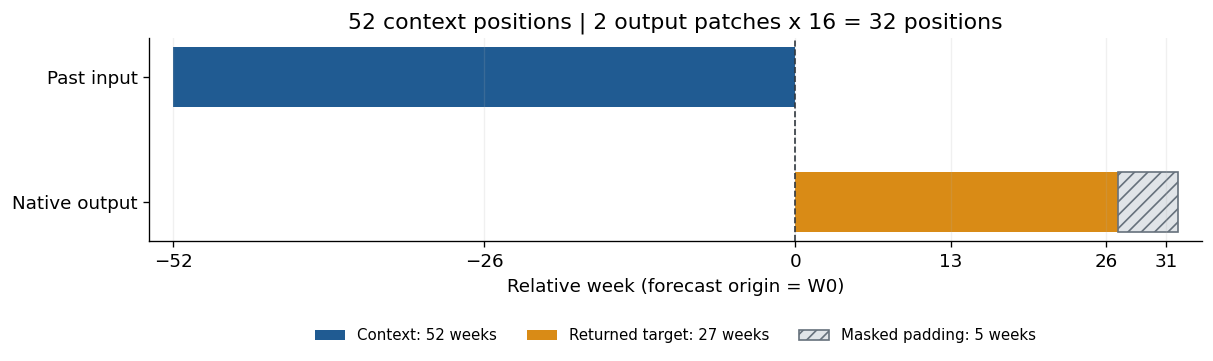

In [8]:
fig, ax = plt.subplots(figsize=(10, 2.8), layout="constrained")
ax.barh(1, LOOKBACK, left=-LOOKBACK, height=0.48, color="#205b92", label="Context: 52 weeks")
ax.barh(0, HORIZON, left=0, height=0.48, color="#d98b16", label="Returned target: 27 weeks")
raw_length = demo_config.num_output_patches * demo_config.patch_size
ax.barh(0, raw_length - HORIZON, left=HORIZON, height=0.48,
        color="#e0e4e8", edgecolor="#66717c", hatch="///", label="Masked padding: 5 weeks")
ax.axvline(0, color="#31383f", linewidth=1, linestyle="--")
ax.set(yticks=[0, 1], yticklabels=["Native output", "Past input"], xlim=(-54, 34),
       xticks=[-52, -26, 0, 13, 26, 31], xlabel="Relative week (forecast origin = W0)",
       title="52 context positions | 2 output patches x 16 = 32 positions")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.36), ncol=3, frameon=False, fontsize=9)
ax.grid(axis="x", alpha=0.18)
plt.show()


## 5. 내부 Raw source로 새 모델 생성

공식 v2.3.2 커밋의 연산 소스를 `Chronos2/native/`에 포함한 구성.
외부 `chronos` 모델이나 Pipeline을 호출하지 않고 내부 `Chronos2CoreConfig`와 `Chronos2Model` 생성자 사용.
주요 연산에 한글 주석을 추가하고 출처·LICENSE·NOTICE·해시를 함께 보존.

아래 셀은 외부 `chronos` import와 사전학습 로딩·다운로드 진입점을 막은 상태에서 모델 생성.
`huggingface_hub`는 다운로드 차단 검사에만 사용하는 기반 라이브러리이며 모델 연산 소스와 구분.
PyTorch·Transformers·einops 같은 기반 라이브러리는 계속 사용하는 구성.

In [9]:
import importlib.abc
from modeling_module.models.Chronos2.native.config import Chronos2CoreConfig
from modeling_module.models.Chronos2.native.model import Chronos2Model as NativeChronos2Model
import huggingface_hub

class RejectExternalChronos(importlib.abc.MetaPathFinder):
    def find_spec(self, fullname, path=None, target=None):
        if fullname.split(".")[0] == "chronos":
            raise AssertionError("외부 chronos import 금지: " + fullname)

blocked_calls = (
    (NativeChronos2Model, "from_pretrained"), (Chronos2CoreConfig, "from_pretrained"),
    (huggingface_hub, "snapshot_download"), (huggingface_hub, "hf_hub_download"),
)
import_guard = RejectExternalChronos()
sys.meta_path.insert(0, import_guard)
try:
    with ExitStack() as guards:
        for owner, name in blocked_calls:
            guards.enter_context(patch.object(owner, name, side_effect=AssertionError("공식 가중치 로딩 금지")))
        model = Chronos2TrainableBackbone(demo_config).eval()
finally:
    sys.meta_path.remove(import_guard)
initialization = model.provenance()
assert initialization["initialization_source"] == "random"
assert initialization["implementation_source"] == "vendored"
assert not initialization["pretrained_weights_loaded"] and not initialization["chronos_package_required"]
assert initialization["parameters"] == initialization["trainable_parameters"] > 0
display(pd.DataFrame([{key: initialization[key] for key in
    ("model_kind", "implementation_source", "pretrained_weights_loaded", "parameters", "trainable_parameters")}]))
print("실제 모델 클래스:", initialization["implementation_module"])
print("초기 가중치 SHA-256:", initialization["initial_parameters_sha256"])

/opt/anaconda3/envs/demand_engine/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,model_kind,implementation_source,pretrained_weights_loaded,parameters,trainable_parameters
0,chronos2_scratch,vendored,False,54304,54304


실제 모델 클래스: modeling_module.models.Chronos2.native.model
초기 가중치 SHA-256: 6a2b85c3b928a2f9482e90aae0e241735373085a2e9c12645c5e1ae11f1f138e


### 실제 내부 모델과 Attention 실행 순서 관찰

아래 출력은 설명용 의사코드가 아니라 현재 실행 중인 내부 파일에서 읽은 메서드.
한 블록에서 Time Attention → Group Attention → Feed Forward 순서로 처리하는 코드 확인.
전체 연산 파일은 출력된 저장소 경로를 열어 확인 가능.

In [10]:
import inspect
from modeling_module.models.Chronos2.native.model import Chronos2EncoderBlock
implementation_file = Path(inspect.getfile(type(model.native_model))).resolve()
assert implementation_file == REPO_ROOT / "src/modeling_module/models/Chronos2/native/model.py"
print("모델 Raw source:", implementation_file.relative_to(REPO_ROOT))
display(Markdown("```python\n" + inspect.getsource(Chronos2EncoderBlock.forward) + "\n```"))

모델 Raw source: src/modeling_module/models/Chronos2/native/model.py


```python
    def forward(
        self,
        hidden_states: torch.Tensor,
        *,
        position_ids: torch.Tensor,
        attention_mask: torch.Tensor,
        group_time_mask: torch.Tensor,
        output_attentions: bool = False,
    ) -> Chronos2EncoderBlockOutput:
        # apply time attention
        time_self_attn_outputs: AttentionOutput = self.layer[0](
            hidden_states,
            position_ids=position_ids,
            attention_mask=attention_mask,
            output_attentions=output_attentions,
        )
        hidden_states = time_self_attn_outputs[0]

        # apply group attention
        group_self_attn_outputs: AttentionOutput = self.layer[1](
            hidden_states, attention_mask=group_time_mask, output_attentions=output_attentions
        )
        hidden_states = group_self_attn_outputs[0]

        # apply feed forward layer
        hidden_states = self.layer[2](hidden_states)

        return Chronos2EncoderBlockOutput(
            hidden_states=hidden_states,
            time_self_attn_weights=time_self_attn_outputs.attn_weights,
            group_self_attn_weights=group_self_attn_outputs.attn_weights,
        )

```

### 같은 seed와 다른 seed 비교

같은 설정·검증 환경·seed이면 같은 초기 파라미터 해시.
seed가 다르면 초기 파라미터도 달라지는 확인.
모델 생성 시 잠시 사용하는 CPU 난수 상태를 복원하므로 호출자의 난수 진행을 변경하지 않는 경계.
서로 다른 하드웨어·PyTorch 버전까지 비트 단위 재현을 보장하는 의미와 구분.


In [11]:
rng_before = torch.get_rng_state().clone()
same_seed_model = Chronos2TrainableBackbone(demo_config)
torch.testing.assert_close(torch.get_rng_state(), rng_before, rtol=0, atol=0)
other_seed_model = Chronos2TrainableBackbone(replace(demo_config, seed=SEED + 1))
same_seed_ok = model.initial_parameters_sha256 == same_seed_model.initial_parameters_sha256
different_seed_ok = model.initial_parameters_sha256 != other_seed_model.initial_parameters_sha256
assert same_seed_ok and different_seed_ok
display(pd.DataFrame([
    {"비교": "동일 seed → 초기 해시 동일", "통과": same_seed_ok},
    {"비교": "다른 seed → 초기 해시 다름", "통과": different_seed_ok},
]))
del same_seed_model, other_seed_model


,비교,통과
0,동일 seed → 초기 해시 동일,True
1,다른 seed → 초기 해시 다름,True


## 6. 작은 합성 수요 배치 구성

두 독립 시계열로 추세·계절형과 간헐형 예제를 생성하는 단계.
실제 부품·실제 원천을 사용하지 않는 합성 자료이며 운영 수요 패턴의 대표 표본과 구분.
첫 행의 과거 위치 하나와 두 번째 행의 미래 위치 하나는 NaN 결측으로 표시.

- `context`: `(N,52)` 과거 입력
- `future_target`: `(N,27)` 손실 계산용 미래 정답
- 각 행에 서로 다른 group ID를 부여해 부품 간 정보 혼합 차단
- 현재 단계는 독립 단변량만 지원하며 target·외생변수의 공유 그룹 학습은 미구현


In [12]:
rng = np.random.default_rng(SEED)
relative_weeks = np.arange(-LOOKBACK, HORIZON)
smooth = np.maximum(0, 24 + 0.08 * relative_weeks
                    + 6 * np.sin(2 * np.pi * relative_weeks / 26)
                    + rng.normal(0, 0.7, len(relative_weeks)))
intermittent = np.where(np.arange(len(relative_weeks)) % 4 == 0,
                        rng.gamma(3, 5, len(relative_weeks)), 0.0)
synthetic_values = np.stack([smooth, intermittent]).astype(np.float32)
context = torch.from_numpy(synthetic_values[:, :LOOKBACK].copy())
future_target = torch.from_numpy(synthetic_values[:, LOOKBACK:].copy())
context[0, 5] = torch.nan
future_target[1, 3] = torch.nan
batch = Chronos2TrainingBatch(context=context, future_target=future_target)
display(pd.DataFrame([
    {"합성 시계열": label, "과거 관측 수": int(torch.isfinite(context[row]).sum()),
     "과거 0수요 수": int((context[row] == 0).sum()),
     "미래 관측 수": int(torch.isfinite(future_target[row]).sum())}
    for row, label in enumerate(("추세·계절형", "간헐형"))
]))


,합성 시계열,과거 관측 수,과거 0수요 수,미래 관측 수
0,추세·계절형,51,0,27
1,간헐형,52,39,26


### 0과 NaN의 실제 마스크 확인

관측 마스크가 True인 0은 손실에 포함할 실제 값.
NaN 또는 False 마스크는 관측되지 않은 위치.
공식 정규화는 `context_mask` 적용보다 먼저 수행되므로, False 위치의 유한한 숫자도 먼저 NaN으로 치환해 스케일 계산에서 제외하는 보완.

입력은 복사본으로 준비하며 원본 Tensor를 변경하지 않는 계약.


In [13]:
prepared = batch.native_inputs(demo_config, "cpu")
assert prepared["context_mask"][1, 1].item()  # 실제 0수요.
assert not prepared["context_mask"][0, 5].item()  # NaN 결측.
assert torch.isnan(prepared["context"][0, 5])
assert prepared["group_ids"].tolist() == [0, 1]
display(pd.DataFrame([
    {"위치": "간헐형 과거 index 1", "입력": float(context[1, 1]),
     "관측 마스크": bool(prepared["context_mask"][1, 1]), "의미": "실제 0수요"},
    {"위치": "계절형 과거 index 5", "입력": float(context[0, 5]),
     "관측 마스크": bool(prepared["context_mask"][0, 5]), "의미": "결측"},
]))


,위치,입력,관측 마스크,의미
0,간헐형 과거 index 1,0.0,True,실제 0수요
1,계절형 과거 index 5,NaN,False,결측


## 7. Native forward와 정확히 27주인 반환값

여기까지의 모델은 **한 번도 갱신하지 않은 랜덤 모델**.
`eval()`과 `no_grad()`는 이 비교에서 dropout·역전파 기록을 끄는 용도이며 학습 가능한 파라미터 자체를 동결하는 조작과 구분.

프로젝트 출력과 native 출력을 대조해 손실·shape가 일치하는지 확인.
P50은 중앙값 점 예측, 21개 분위수는 `(N,27,21)`.
랜덤 모델은 분위수 순서가 뒤집히거나 음수를 출력할 수 있으므로 보정·재정렬 없이 원 출력 유지.


In [14]:
def evaluate(values):
    model.eval()
    with torch.no_grad():
        return model(values)

initial_output = evaluate(batch)
with torch.no_grad():
    native_output = model.native_model(**prepared, num_output_patches=demo_config.num_output_patches)
torch.testing.assert_close(initial_output.loss, native_output.loss, rtol=0, atol=0)
assert initial_output.point.shape == (2, 27, 1)
assert initial_output.quantiles.shape == (2, 27, 21)
assert initial_output.raw_prediction_length == 32
assert initial_output.observed_target_points == 53
display(pd.DataFrame([
    {"출력": "native 분위수", "shape": str(tuple(native_output.quantile_preds.shape))},
    {"출력": "반환 분위수", "shape": str(tuple(initial_output.quantiles.shape))},
    {"출력": "P50 점 예측", "shape": str(tuple(initial_output.point.shape))},
]))
print(f"갱신 전 native loss: {float(initial_output.loss):.8f}")


,출력,shape
0,native 분위수,"(2, 21, 32)"
1,반환 분위수,"(2, 27, 21)"
2,P50 점 예측,"(2, 27, 1)"


갱신 전 native loss: 12.54170609


### 랜덤 초기화 예측을 그림으로 확인

회색은 합성 정답, 파란 점선은 미학습 모델의 P50 출력.
같은 단위로 그려 출력 위치·길이·역정규화 결과를 관찰하는 그림이며 성능 평가와 구분.
NaN 위치는 빈 구간으로 유지하고 0수요로 그리지 않는 방식.
학습 전 분위수는 정렬·보정되지 않았으므로 신뢰구간처럼 채색하지 않은 구성.


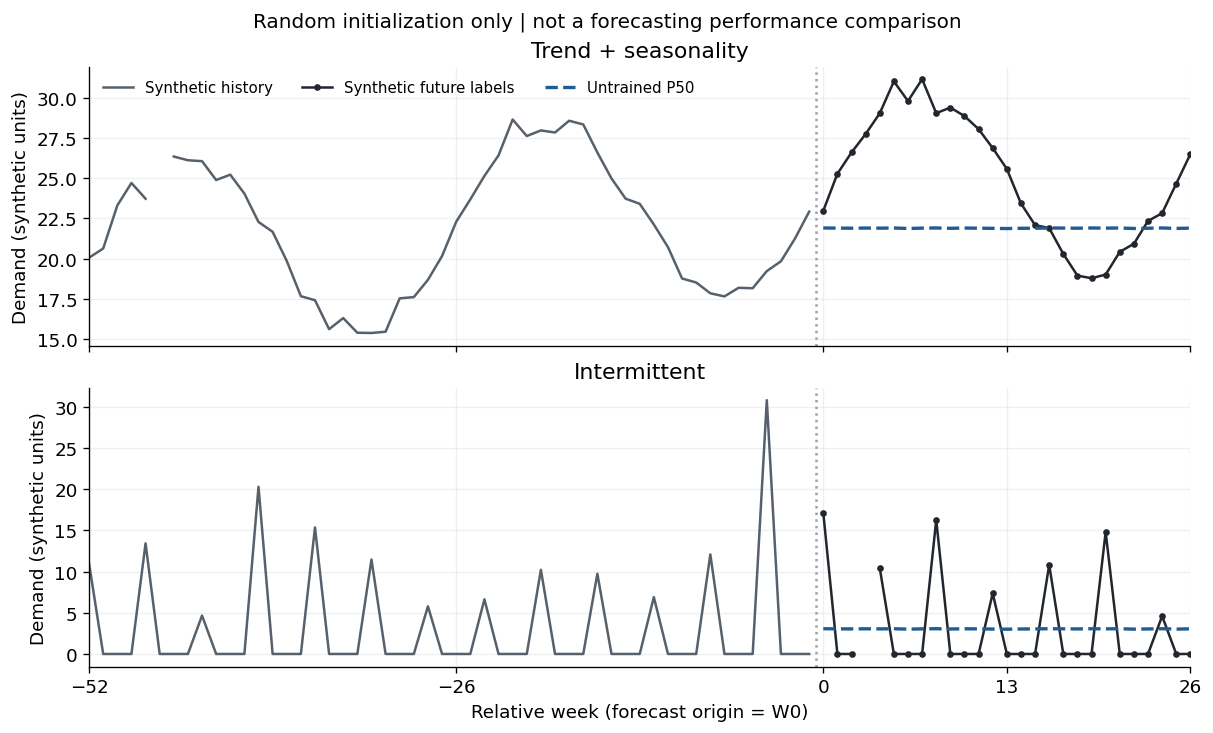

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout="constrained")
for row, (axis, label) in enumerate(zip(axes, ("Trend + seasonality", "Intermittent"))):
    axis.plot(np.arange(-LOOKBACK, 0), context[row].numpy(), color="#56616c", label="Synthetic history")
    axis.plot(np.arange(HORIZON), future_target[row].numpy(), color="#22272e",
              marker="o", markersize=3, label="Synthetic future labels")
    axis.plot(np.arange(HORIZON), initial_output.point[row, :, 0].numpy(),
              color="#205b92", linestyle="--", linewidth=2, label="Untrained P50")
    axis.axvline(-0.5, color="#9aa3ab", linestyle=":")
    axis.set(title=label, ylabel="Demand (synthetic units)", xlim=(-52, 26))
    axis.grid(alpha=0.18)
axes[0].legend(loc="upper left", ncol=3, fontsize=9, frameon=False)
axes[-1].set(xticks=[-52, -26, 0, 13, 26], xlabel="Relative week (forecast origin = W0)")
fig.suptitle("Random initialization only | not a forecasting performance comparison", fontsize=12)
plt.show()


## 8. 학습 손실과 패딩

과거 복원 MSE나 원 수량 단위 MAE가 아닌 **정규화 공간의 미래 분위수 손실**.
독립 target 행만 있는 현재 실습에서 공식 구현의 합산 방식은 다음과 같은 형태.

\[
\rho_q(e)=\max(qe,(q-1)e),\qquad
L=\frac1N\sum_i\sum_q\frac1{32}\sum_{t=1}^{32}m_{it}\,2\rho_q(y'_{it}-\hat y'_{itq})
\]

$y'$와 $\hat y'$는 context 기준 정규화·설정된 변환 공간의 정답과 예측.
관측 정답만 마스크 1이며 나머지·패딩은 0.
**분모는 유효 정답 수 27이 아니라 패딩을 포함한 raw 길이 32**인 공식 동작 유지.
따라서 관측 수가 다른 배치의 loss 크기를 원 단위 예측 성능처럼 직접 해석하지 않는 기준.

다음 셀은 남는 5개에 매우 큰 가짜 정답을 넣어도 마스크가 0이면 손실에 영향이 없는지 확인.


### 실제 손실 계산 Raw source

내부 `_compute_loss` 메서드에서 context 기준 변환, 정답·패딩 마스크, 시간 평균·분위수 합산을 확인하는 셀.
공식 수식은 그대로 유지하며 프로젝트의 배치 검사는 이 메서드 호출 전에 수행하는 구조.

In [16]:
display(Markdown("```python\n" + inspect.getsource(NativeChronos2Model._compute_loss) + "\n```"))

```python
    def _compute_loss(
        self,
        quantile_preds: torch.Tensor,
        future_target: torch.Tensor,
        future_target_mask: torch.Tensor | None,
        patched_future_covariates_mask: torch.Tensor,
        loc_scale: tuple[torch.Tensor, torch.Tensor],
        num_output_patches: int,
    ) -> torch.Tensor:
        batch_size = future_target.shape[0]
        output_patch_size = self.chronos_config.output_patch_size
        assert quantile_preds.shape[0] == batch_size and quantile_preds.shape[-1] >= future_target.shape[-1]

        # normalize target and mask
        future_target, _ = self.instance_norm(future_target, loc_scale)
        future_target = future_target.unsqueeze(1)
        future_target = future_target.to(self.device)
        future_target_mask = (
            future_target_mask.unsqueeze(1).to(self.device)
            if future_target_mask is not None
            else ~torch.isnan(future_target)
        )
        future_target = torch.where(future_target_mask > 0.0, future_target, 0.0)

        # pad target and target_mask if they are shorter than model's prediction
        if quantile_preds.shape[-1] > future_target.shape[-1]:
            padding_shape = (*future_target.shape[:-1], quantile_preds.shape[-1] - future_target.shape[-1])
            future_target = torch.cat([future_target, torch.zeros(padding_shape).to(future_target)], dim=-1)
            future_target_mask = torch.cat(
                [future_target_mask, torch.zeros(padding_shape).to(future_target_mask)], dim=-1
            )

        quantiles = rearrange(self.quantiles, "num_quantiles -> 1 num_quantiles 1")
        quantile_loss = 2 * torch.abs(
            (future_target - quantile_preds) * ((future_target <= quantile_preds).float() - quantiles)
        )
        inv_future_covariate_mask = 1 - rearrange(
            patched_future_covariates_mask,
            "b n p -> b 1 (n p)",
            b=batch_size,
            n=num_output_patches,
            p=output_patch_size,
        )
        # the first components masks any missing targets and the second component masks known future values
        loss_mask = future_target_mask.float() * inv_future_covariate_mask
        loss = quantile_loss * loss_mask
        # mean over prediction horizon, sum over quantile levels and mean over batch
        loss = loss.mean(dim=-1).sum(dim=-1).mean()

        return loss

```

In [17]:
padding = raw_length - HORIZON
extended_inputs = {
    **prepared,
    "future_target": torch.cat([prepared["future_target"], torch.full((2, padding), 99999.0)], dim=1),
    "future_target_mask": torch.cat([prepared["future_target_mask"],
                                     torch.zeros(2, padding, dtype=torch.bool)], dim=1),
}
with torch.no_grad():
    padded_output = model.native_model(**extended_inputs, num_output_patches=demo_config.num_output_patches)
torch.testing.assert_close(initial_output.loss, padded_output.loss, rtol=0, atol=0)
padding_ok = True
display(pd.DataFrame({"조건": ["정답 27개 + native 자동 패딩", "큰 가짜 정답 5개 + 마스크 0"],
                      "native loss": [float(initial_output.loss), float(padded_output.loss)]}))


,조건,native loss
0,정답 27개 + native 자동 패딩,12.541706
1,큰 가짜 정답 5개 + 마스크 0,12.541706


## 9. 누수 방지 검사

동일 모델과 dropout이 꺼진 조건에서 입력의 일부만 바꿔 비교하는 검사.

| 검사 | 바꾸는 값 | 변하면 안 되는 값 |
|---|---|---|
| 숨긴 과거 | False 마스크 위치의 숫자 | 예측과 손실 |
| 미래 정답 | 정답 수량 100배 | 예측값; 손실은 바뀌는 것이 정상 |
| 독립 부품 | 두 번째 행 과거 1,000배 | 첫 번째 행 예측 |

분할·sampler 전체의 누수 검증을 대신하는 검사는 아니며 backbone의 현재 경계를 확인하는 범위.


In [18]:
history_mask = torch.isfinite(context)
history_mask[:, :3] = False
masked_batch = replace(batch, context_mask=history_mask)
masked_reference = evaluate(masked_batch)
modified_context = context.clone()
modified_context[:, :3] = 999999.0
hidden_changed = evaluate(replace(masked_batch, context=modified_context))
torch.testing.assert_close(masked_reference.point, hidden_changed.point, rtol=0, atol=0)
torch.testing.assert_close(masked_reference.loss, hidden_changed.loss, rtol=0, atol=0)

labels_changed = evaluate(replace(batch, future_target=future_target * 100))
torch.testing.assert_close(initial_output.point, labels_changed.point, rtol=0, atol=0)
assert not torch.equal(initial_output.loss, labels_changed.loss)

other_context = context.clone()
other_context[1] *= 1000
other_changed = evaluate(replace(batch, context=other_context))
torch.testing.assert_close(initial_output.point[0], other_changed.point[0], rtol=0, atol=0)
leakage_ok = True
display(pd.DataFrame([
    {"검사": "숨긴 값 변경 → 예측·loss 동일", "통과": True},
    {"검사": "정답 변경 → 예측 동일, loss 변경", "통과": True},
    {"검사": "독립 부품 변경 → 첫 행 예측 동일", "통과": True},
]))


,검사,통과
0,숨긴 값 변경 → 예측·loss 동일,True
1,"정답 변경 → 예측 동일, loss 변경",True
2,독립 부품 변경 → 첫 행 예측 동일,True


## 10. 합성 배치에서 실제 역전파 1회

앞의 진단용 모델과 별도로 같은 seed의 새 모델을 생성해 AdamW를 딱 한 번 수행.
이 셀만 다시 실행해도 새 모델에서 1회 수행하는 구성.
gradient가 유한하고 output head의 가중치가 바뀌는지 확인하는 목적.

아래 before/after loss는 **같은 합성 배치**의 값이며 검증 성능이나 일반화 성능과 구분.
loss 감소 자체를 통과 조건으로 사용하지 않고 실제 gradient·파라미터 갱신을 확인.
`provenance()`의 초기 해시는 갱신 후 현재 가중치가 아닌 생성 당시 가중치의 추적값.


In [19]:
step_model = Chronos2TrainableBackbone(demo_config).train()
head_weight = step_model.native_model.output_patch_embedding.output_layer.weight
before_weight = head_weight.detach().clone()
optimizer = torch.optim.AdamW(step_model.parameters(), lr=1e-3)
optimizer.zero_grad()
step_before = step_model(batch)
step_before.loss.backward()
assert head_weight.grad is not None and torch.isfinite(head_weight.grad).all()
gradient_norm = float(head_weight.grad.norm())
assert gradient_norm > 0
optimizer.step()
max_weight_change = float((head_weight.detach() - before_weight).abs().max())
assert max_weight_change > 0
step_model.eval()
with torch.no_grad():
    step_after = step_model(batch)
update_ok = True
display(pd.DataFrame([{
    "합성 optimizer step": 1, "갱신 전 native loss": float(step_before.loss.detach()),
    "갱신 후 native loss": float(step_after.loss), "head gradient norm": gradient_norm,
    "head 최대 가중치 변화": max_weight_change,
}]))


,합성 optimizer step,갱신 전 native loss,갱신 후 native loss,head gradient norm,head 최대 가중치 변화
0,1,12.541706,12.500884,0.011425,0.001


## 11. 0수요와 잘못된 입력 검사

전부 0인 실제 관측은 유효한 배치이며, 전부 결측인 정답은 유효하지 않은 배치.
음수·Inf·잘못된 H·빈 정답 마스크를 loss 0의 성공으로 처리하지 않는 정책.
전부 0인 관측의 loss가 작다는 이유만으로 오류로 판정하지 않는 구분.

공유 group ID도 현재 단변량 계약에서는 거부. Group Attention 연산 코드의 존재와
외생변수·부품 간 공유 그룹 학습을 검증했다는 주장은 별개의 범위.


In [20]:
zero_batch = Chronos2TrainingBatch(torch.zeros(2, LOOKBACK), torch.zeros(2, HORIZON))
zero_inputs = zero_batch.native_inputs(demo_config, "cpu")
zero_output = evaluate(zero_batch)
assert int(zero_inputs["future_target_mask"].sum()) == 54
assert torch.isfinite(zero_output.loss)
invalid_cases = [
    ("음수 관측 수요", replace(batch, future_target=-torch.ones(2, HORIZON))),
    ("관측 정답 전부 결측", replace(batch, future_target=torch.full((2, HORIZON), torch.nan))),
    ("정답 마스크 전부 False", replace(batch, future_target_mask=torch.zeros(2, HORIZON, dtype=torch.bool))),
    ("H27 대신 H26", replace(batch, future_target=torch.ones(2, HORIZON - 1))),
    ("독립 행이 같은 그룹 사용", replace(batch, group_ids=torch.tensor([1, 1]))),
]
rejection_rows = [expect_rejection(label, lambda values=values: values.native_inputs(demo_config, "cpu"))
                  for label, values in invalid_cases]
assert len(rejection_rows) == 5
print("전부 0인 배치의 실제 관측 정답 수:", zero_output.observed_target_points)
display(pd.DataFrame(rejection_rows))


전부 0인 배치의 실제 관측 정답 수: 54


,검사,결과,메시지
0,음수 관측 수요,예상대로 거부,future_target의 관측 수량은 유한한 0 이상의 값이어야 합니다.
1,관측 정답 전부 결측,예상대로 거부,future_target의 각 행에 실제 관측값이 하나 이상 필요합니다.
2,정답 마스크 전부 False,예상대로 거부,future_target의 각 행에 실제 관측값이 하나 이상 필요합니다.
3,H27 대신 H26,예상대로 거부,"future_target은 계약의 (N,horizon)과 정확히 일치해야 합니다."
4,독립 행이 같은 그룹 사용,예상대로 거부,현재 단계는 독립 단변량만 지원하므로 group ID는 행마다 달라야 합니다.


## 실행 결과 요약

아래 표는 이 커널에서 직접 실행한 실습 검사 결과.
로컬 manifest가 없는 환경은 해당 항목만 `건너뜀`으로 표시.
전 단계 전체 pytest 결과를 이 노트북이 새로 실행한 것으로 표시하지 않는 구분.


In [21]:
checks = [
    ("합성 부품·기간 계약 및 cutoff", True),
    ("현재 로컬 manifest 해시·교집합", saved_manifest_verified),
    ("공식 가중치 로딩 함수 차단 중 생성", not initialization["pretrained_weights_loaded"]),
    ("동일 seed 재현·다른 seed 구분", same_seed_ok and different_seed_ok),
    ("H27 반환·native 손실 일치", initial_output.point.shape == (2, 27, 1)),
    ("패딩 5개 손실 제외", padding_ok),
    ("backbone 누수 경계", leakage_ok),
    ("합성 AdamW 1회 가중치 갱신", update_ok),
    ("0수요 허용·잘못된 입력 거부", len(rejection_rows) == 5),
]
assert all(result is None or bool(result) for _, result in checks)
display(pd.DataFrame([{"검사": label, "이번 실행": "건너뜀" if result is None else "통과"}
                      for label, result in checks]))
print("실데이터 학습: 미실행 / DB 쓰기: 미실행 / GPU: 미사용 / optimizer 갱신: 합성 1회")


,검사,이번 실행
0,합성 부품·기간 계약 및 cutoff,통과
1,현재 로컬 manifest 해시·교집합,통과
2,공식 가중치 로딩 함수 차단 중 생성,통과
3,동일 seed 재현·다른 seed 구분,통과
4,H27 반환·native 손실 일치,통과
5,패딩 5개 손실 제외,통과
6,backbone 누수 경계,통과
7,합성 AdamW 1회 가중치 갱신,통과
8,0수요 허용·잘못된 입력 거부,통과


실데이터 학습: 미실행 / DB 쓰기: 미실행 / GPU: 미사용 / optimizer 갱신: 합성 1회


## 다음 작업과 참고 자료

**시간 창과 패턴별 표집 구성 · 다음 작업**

고정된 분할을 유지하면서 실제 수량 품질과 L52/H27 이력 가용성을 검사할 단계.
유효 창 수·제외 사유 기록과 context만을 사용한 패턴별 균형 표집이 완료 기준.

**Trainer와 자체 체크포인트 연결 · 이후 작업**

학습 반복·검증·중단·저장·재시작·자체 가중치 추론을 연결할 단계.
저장 전후 H27 예측 일치와 통제된 중단·재개 재현을 확인할 대상.

**제한된 실데이터 GPU 실험 · 승인 필요**

합성 통합 검증 후 대상 장치·데이터 범위·step·시간 예산을 별도 확정할 단계.
실제 수요 학습과 5090 실행은 이 노트북의 자동 실행 범위에서 제외.

참고:

- [데이터·backbone 개발 문서](../../../../../docs/Chronos2PretrainingContracts.md)
- [2026-11-19 검증 증적](../../../../../docs/evidence/Chronos2PretrainingContracts20261119.json)
- [내부 모델 원본](../native/model.py), [Attention 원본](../native/layers.py), [정규화·패치](../native/preprocessing.py)
- [학습용 backbone](../trainable_backbone.py), [배치 계약](../training/batch.py), [분할 계약](../training/contracts.py)
- [공식 v2.3.2 모델 코드](https://github.com/amazon-science/chronos-forecasting/blob/v2.3.2/src/chronos/chronos2/model.py)

이전 코드 회귀 증적: 신규 테스트 55개 통과, 전체 1,028 passed / CUDA 6 skipped / 46 subtests passed.
위 수치는 이전 pytest 실행 기록이며 이번 노트북 실행 결과는 바로 위 표에서 별도로 확인하는 구성.
